# Olist E-commerce: Customer Retention & Delivery Impact Analysis

**Business problem.** Olist is a Brazilian marketplace that connects small sellers to large online stores. Growth depends on two things this notebook measures:

1. **Delivery experience:** do late deliveries damage customer satisfaction, and where and when does lateness happen?
2. **Retention:** do customers come back, and which customers are worth targeting?

**Data:** Brazilian E-Commerce Public Dataset by Olist (Kaggle). About 99k orders from Sep 2016 to Oct 2018 across 8 related tables.

**Outputs:** cleaned analysis tables in `Data/Processed/`, which the SQL scripts and the dashboard use.

Run the cells top to bottom from the `Python/` folder.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

RAW = "../Data/Raw/"
OUT = "../Data/Processed/"

# Consistent, readable chart style
plt.rcParams.update({
    "figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 12,
})
BLUE, ORANGE, RED, GREY = "#2a78d6", "#eb6834", "#e34948", "#898781"

## 2. Load the raw tables

In [2]:
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]

orders = pd.read_csv(RAW + "olist_orders_dataset.csv", parse_dates=date_cols)
customers = pd.read_csv(RAW + "olist_customers_dataset.csv")
items = pd.read_csv(RAW + "olist_order_items_dataset.csv")
payments = pd.read_csv(RAW + "olist_order_payments_dataset.csv")
reviews = pd.read_csv(RAW + "olist_order_reviews_dataset.csv", parse_dates=["review_creation_date", "review_answer_timestamp"])
products = pd.read_csv(RAW + "olist_products_dataset.csv")
sellers = pd.read_csv(RAW + "olist_sellers_dataset.csv")
translation = pd.read_csv(RAW + "product_category_name_translation.csv")

tables = {"orders": orders, "customers": customers, "items": items, "payments": payments,
          "reviews": reviews, "products": products, "sellers": sellers, "translation": translation}
pd.DataFrame({name: {"rows": len(df), "columns": df.shape[1], "missing_cells": int(df.isna().sum().sum())}
              for name, df in tables.items()}).T

,rows,columns,missing_cells
orders,99441,8,4908
customers,99441,5,0
items,112650,7,0
payments,103886,5,0
reviews,99224,7,145903
products,32951,9,2448
sellers,3095,4,0
translation,71,2,0


## 3. Data profiling

Before cleaning, check the things that would silently break the analysis: order status mix, date coverage, missing values, duplicate keys, and whether the tables join cleanly.

In [3]:
orders['order_status'].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [4]:
monthly_raw = orders.groupby(orders["order_purchase_timestamp"].dt.to_period("M")).size()
print("First order:", orders["order_purchase_timestamp"].min(), "| Last order:", orders["order_purchase_timestamp"].max())
monthly_raw.head(4), monthly_raw.tail(4)

First order: 2016-09-04 21:15:19 | Last order: 2018-10-17 17:30:18


(order_purchase_timestamp
2016-09      4
2016-10    324
2016-12      1
2017-01    800
Freq: M, dtype: int64, order_purchase_timestamp
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, dtype: int64)

In [5]:
checks = {
    "orders missing delivered date": orders["order_delivered_customer_date"].isna().sum(),
    "orders with no items": (~orders["order_id"].isin(items["order_id"])).sum(),
    "orders with no payment": (~orders["order_id"].isin(payments["order_id"])).sum(),
    "orders with more than one review": reviews["order_id"].duplicated().sum(),
    "duplicate review_id": reviews["review_id"].duplicated().sum(),
    "products with no category": products["product_category_name"].isna().sum(),
    "categories missing an English name": len(set(products["product_category_name"].dropna()) - set(translation["product_category_name"])),
    "customer_id values": customers["customer_id"].nunique(),
    "customer_unique_id values": customers["customer_unique_id"].nunique(),
}
pd.Series(checks, name="count")

orders missing delivered date          2965
orders with no items                    775
orders with no payment                    1
orders with more than one review        551
duplicate review_id                     814
products with no category               610
categories missing an English name        2
customer_id values                    99441
customer_unique_id values             96096
Name: count, dtype: int64

**What the profiling tells us**

- **`customer_id` is not a customer.** Olist creates a new `customer_id` for every order. The real person is `customer_unique_id`, and using the wrong key would make repeat purchases look like zero.
- **The edges of the timeline are sparse.** 2016 has only a few hundred orders, and Sep–Oct 2018 has a handful of unfinished orders. Trends would be distorted by these partial months.
- **Some orders have several reviews**, so reviews must be de-duplicated before joining or those orders get double-counted.
- **Some orders have no items or no delivery date.** These are cancelled, unavailable or still in transit.

## 4. Cleaning rules

| Rule | Reason |
|---|---|
| Keep `delivered` orders with a delivered date and at least one item | Delivery time, lateness and reviews only make sense for completed orders |
| Keep purchases from 2017-01-01 to 2018-08-31 | Removes the sparse 2016 start and the incomplete Sep–Oct 2018 tail |
| One review per order: keep the latest answered review | Prevents double counting |
| Order revenue = item prices + freight (from `order_items`) | `payments` can split one order into several rows; items are the source of truth for value |
| Main category = category of the order's most expensive item | Gives each order one category for analysis |
| Missing categories → `unknown`; two untranslated categories translated manually | Keeps every order in category totals |
| Late = delivered **after** the estimated delivery date (by calendar day) | The estimate is a date, not a time |

In [6]:
# Category names in English (two are missing from the translation file)
translation = pd.concat([translation, pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos"],
    "product_category_name_english": ["pc_gamer", "kitchen_portables_and_food_preparers"]})])
products = products.merge(translation, on="product_category_name", how="left")
products["category"] = products["product_category_name_english"].fillna("unknown")

# Order-level item totals and main category
items_cat = items.merge(products[["product_id", "category"]], on="product_id", how="left")
order_items = items_cat.groupby("order_id").agg(
    items=("order_item_id", "count"),
    sellers=("seller_id", "nunique"),
    product_value=("price", "sum"),
    freight_value=("freight_value", "sum"),
)
main_cat = (items_cat.sort_values(["order_id", "price"], ascending=[True, False])
            .drop_duplicates("order_id").set_index("order_id")["category"].rename("main_category"))

# One review per order: the latest one answered
review_one = (reviews.sort_values("review_answer_timestamp")
              .drop_duplicates("order_id", keep="last")
              .set_index("order_id")[["review_score"]])

# Payment summary per order: method of the largest payment, max instalments
pay_main = (payments.sort_values(["order_id", "payment_value"], ascending=[True, False])
            .drop_duplicates("order_id").set_index("order_id")["payment_type"])
pay_summary = payments.groupby("order_id").agg(installments=("payment_installments", "max"),
                                               payment_value=("payment_value", "sum"))
pay_summary["payment_type"] = pay_main
print(order_items.shape, main_cat.shape, review_one.shape, pay_summary.shape)

(98666, 4) (98666,) (98673, 1) (99440, 3)


In [7]:
in_scope = (
    (orders["order_status"] == "delivered")
    & orders["order_delivered_customer_date"].notna()
    & (orders["order_purchase_timestamp"] >= "2017-01-01")
    & (orders["order_purchase_timestamp"] < "2018-09-01")
    & orders["order_id"].isin(order_items.index)
)
df = (orders[in_scope]
      .merge(customers[["customer_id", "customer_unique_id", "customer_city", "customer_state"]], on="customer_id")
      .join(order_items, on="order_id")
      .join(main_cat, on="order_id")
      .join(review_one, on="order_id")
      .join(pay_summary, on="order_id"))

df["order_value"] = df["product_value"] + df["freight_value"]
df["purchase_month"] = df["order_purchase_timestamp"].dt.to_period("M").astype(str)
df["delivery_days"] = (df["order_delivered_customer_date"] - df["order_purchase_timestamp"]).dt.total_seconds() / 86400
df["delay_days"] = (df["order_delivered_customer_date"].dt.normalize() - df["order_estimated_delivery_date"].dt.normalize()).dt.days
df["is_late"] = (df["delay_days"] > 0).astype(int)

print(f"Orders kept: {len(df):,} of {len(orders):,} ({len(df)/len(orders):.1%})")
print("Duplicate order_id after joins:", df["order_id"].duplicated().sum())
print("Orders without a review:", df["review_score"].isna().sum())
print("Orders where payments differ from items by > R$1:", ((df["payment_value"] - df["order_value"]).abs() > 1).sum())

Orders kept: 96,203 of 99,441 (96.7%)
Duplicate order_id after joins: 0
Orders without a review: 643
Orders where payments differ from items by > R$1: 241


A few orders have payments that don't match the item totals (vouchers or rounding). Revenue therefore uses item value, as defined above. No orders were duplicated by the joins.

In [8]:
import os
os.makedirs(OUT, exist_ok=True)
keep = ["order_id", "customer_unique_id", "customer_state", "customer_city", "order_purchase_timestamp", "purchase_month",
        "order_estimated_delivery_date", "order_delivered_customer_date", "items", "sellers", "product_value",
        "freight_value", "order_value", "main_category", "delivery_days", "delay_days", "is_late",
        "review_score", "payment_type", "installments"]
df[keep].to_csv(OUT + "orders_clean.csv", index=False)
df[keep].head(3)

,order_id,customer_unique_id,customer_state,customer_city,order_purchase_timestamp,purchase_month,order_estimated_delivery_date,order_delivered_customer_date,items,sellers,product_value,freight_value,order_value,main_category,delivery_days,delay_days,is_late,review_score,payment_type,installments
0,e481f51cbdc54678b7cc49136f2d6af7,7c396fd4830fd04220f754e42b4e5bff,SP,sao paulo,2017-10-02 10:56:33,2017-10,2017-10-18,2017-10-10 21:25:13,1,1,29.99,8.72,38.71,housewares,8.436574,-8,0,4.0,voucher,1
1,53cdb2fc8bc7dce0b6741e2150273451,af07308b275d755c9edb36a90c618231,BA,barreiras,2018-07-24 20:41:37,2018-07,2018-08-13,2018-08-07 15:27:45,1,1,118.70,22.76,141.46,perfumery,13.782037,-6,0,4.0,boleto,1
2,47770eb9100c2d0c44946d9cf07ec65d,3a653a41f6f9fc3d2a113cf8398680e8,GO,vianopolis,2018-08-08 08:38:49,2018-08,2018-09-04,2018-08-17 18:06:29,1,1,159.90,19.22,179.12,auto,9.394213,-18,0,5.0,credit_card,3


# Analysis

## 5. Business overview

In [9]:
kpis = pd.Series({
    "Delivered orders": len(df),
    "Customers": df["customer_unique_id"].nunique(),
    "Revenue (R$)": df["order_value"].sum(),
    "Average order value (R$)": df["order_value"].mean(),
    "Avg delivery time (days)": df["delivery_days"].mean(),
    "Late delivery rate (%)": df["is_late"].mean() * 100,
    "Average review score": df["review_score"].mean(),
}).round(2)
kpis

Delivered orders               96203.00
Customers                      93096.00
Revenue (R$)                15371741.09
Average order value (R$)         159.78
Avg delivery time (days)          12.54
Late delivery rate (%)             6.79
Average review score               4.16
dtype: float64

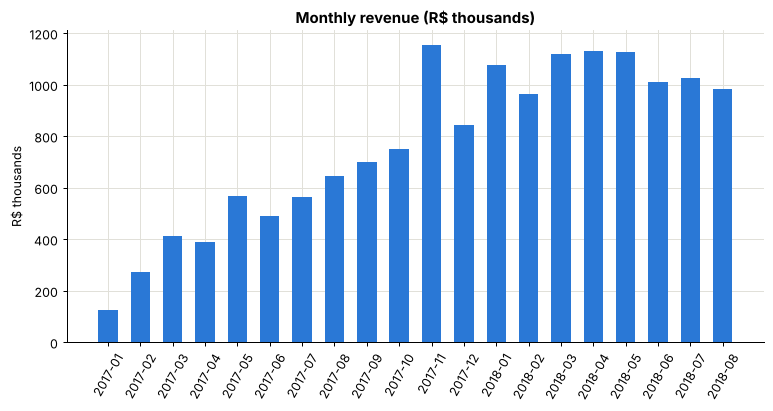

purchase_month,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
orders,750.000,1653.000,2546.000,2303.000,3545.000,3135.000,3872.000,4193.000,4150.000,4478.000,7288.000,5513.000,7069.000,6555.000,7003.000,6798.000,6749.000,6096.000,6156.000,6351.000
revenue,127482.370,271239.320,414330.950,390812.400,566657.400,490050.370,566299.080,645832.360,701077.490,751117.010,1153229.370,843078.290,1077887.460,966168.410,1120598.240,1132878.930,1128774.520,1011448.960,1027286.520,985491.640
late_rate,0.029,0.030,0.046,0.066,0.030,0.030,0.028,0.029,0.044,0.042,0.124,0.075,0.057,0.141,0.190,0.045,0.066,0.012,0.034,0.062
avg_review,4.198,4.203,4.187,4.135,4.236,4.223,4.260,4.313,4.268,4.205,3.989,4.088,4.109,3.881,3.813,4.206,4.236,4.307,4.317,4.310


In [10]:
monthly = df.groupby("purchase_month").agg(orders=("order_id", "count"), revenue=("order_value", "sum"),
                                           late_rate=("is_late", "mean"), avg_review=("review_score", "mean"))
fig, ax = plt.subplots()
ax.bar(monthly.index, monthly["revenue"] / 1e3, color=BLUE, width=0.6)
ax.set_title("Monthly revenue (R$ thousands)")
ax.set_ylabel("R$ thousands")
ax.tick_params(axis="x", rotation=60)
plt.show()
monthly.round(3).T

Revenue grew roughly 8x from Jan 2017 to early 2018 and then levelled off at about R$1M a month. **November 2017 (Black Friday) is the largest month**, which matters for the delivery analysis below.

Top 10 categories = 62.4% of revenue across 74 categories


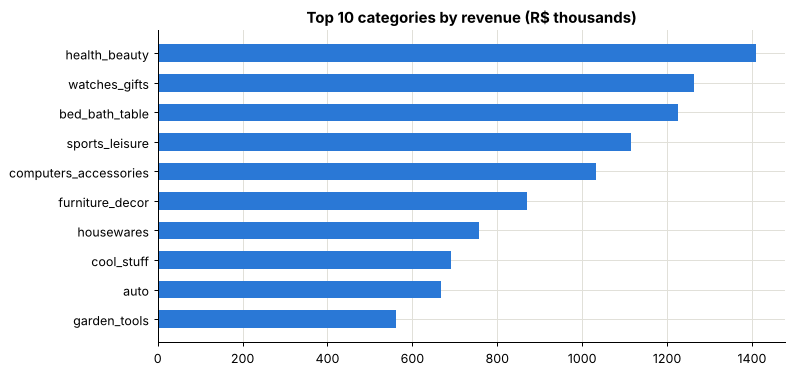

,orders,revenue,avg_review,late_rate
main_category,,,,
health_beauty,8576,1408570.00,4.235,0.075
watches_gifts,5472,1262536.79,4.122,0.074
bed_bath_table,9180,1225771.68,4.007,0.075
sports_leisure,7475,1115007.45,4.235,0.066
computers_accessories,6499,1031751.68,4.084,0.064
furniture_decor,6140,870059.22,4.080,0.073
housewares,5671,756347.77,4.205,0.054
cool_stuff,3523,690813.96,4.230,0.059
auto,3784,668324.58,4.154,0.073


In [11]:
cat = (df.groupby("main_category").agg(orders=("order_id", "count"), revenue=("order_value", "sum"),
                                       avg_review=("review_score", "mean"), late_rate=("is_late", "mean"))
       .sort_values("revenue", ascending=False))
top = cat.head(10)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top.index[::-1], top["revenue"][::-1] / 1e3, color=BLUE, height=0.6)
ax.set_title("Top 10 categories by revenue (R$ thousands)")
plt.show()
print(f"Top 10 categories = {top['revenue'].sum() / cat['revenue'].sum():.1%} of revenue across {len(cat)} categories")
top.round(3)

## 6. Delivery performance

Median delivery: 10.2 days | median arrival 12 days BEFORE estimate
Delivered on or before estimate: 93.2%


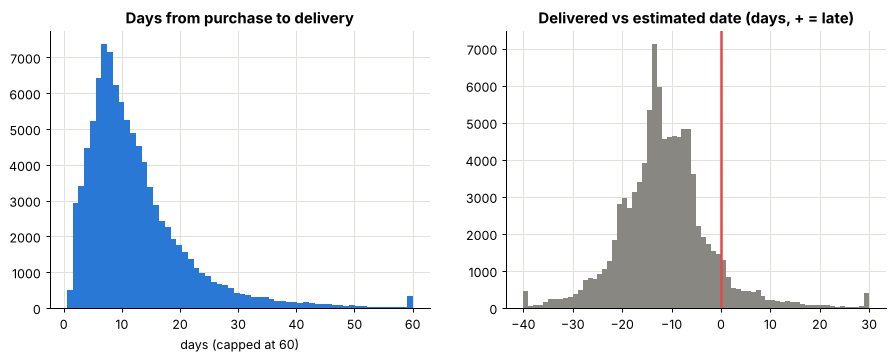

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["delivery_days"].clip(upper=60), bins=60, color=BLUE)
axes[0].set_title("Days from purchase to delivery")
axes[0].set_xlabel("days (capped at 60)")
axes[1].hist(df["delay_days"].clip(-40, 30), bins=70, color=GREY)
axes[1].axvline(0, color=RED, linewidth=2)
axes[1].set_title("Delivered vs estimated date (days, + = late)")
plt.show()
print(f"Median delivery: {df['delivery_days'].median():.1f} days | median arrival {-df['delay_days'].median():.0f} days BEFORE estimate")
print(f"Delivered on or before estimate: {(df['delay_days'] <= 0).mean():.1%}")

**The estimated delivery dates are heavily padded.** The typical order arrives about 12 days before its estimate. That keeps the late rate low on paper, but it also means customers are told to wait much longer than they actually need to, which can hurt conversion at checkout.

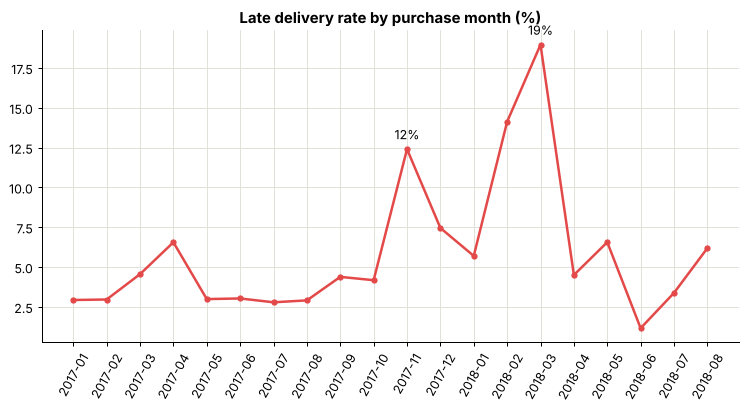

In [13]:
fig, ax = plt.subplots()
ax.plot(monthly.index, monthly["late_rate"] * 100, color=RED, linewidth=2, marker="o", markersize=4)
ax.set_title("Late delivery rate by purchase month (%)")
ax.tick_params(axis="x", rotation=60)
for m in ["2017-11", "2018-03"]:
    ax.annotate(f"{monthly.loc[m, 'late_rate']:.0%}", (m, monthly.loc[m, "late_rate"] * 100),
                textcoords="offset points", xytext=(0, 8), ha="center")
plt.show()

Lateness is not constant. It spiked to **12% in Nov 2017 (Black Friday)** and **14–19% in Feb–Mar 2018**, then dropped back. Lateness tracks how well capacity keeps up with order volume, not just a fixed rate.

Correlation across states (delivery days vs review): -0.46


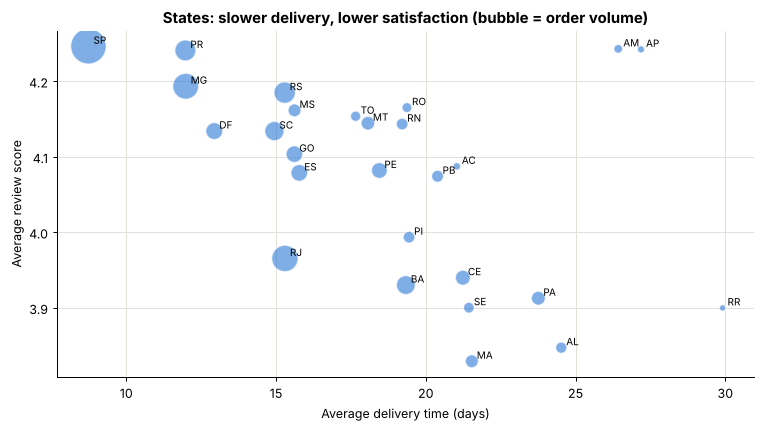

,orders,avg_delivery_days,late_rate,avg_review
customer_state,,,,
SP,40399,8.738,0.045,4.247
PR,4903,11.973,0.041,4.241
MG,11319,11.985,0.046,4.194
DF,2074,12.939,0.057,4.134
SC,3537,14.946,0.082,4.134
RS,5327,15.289,0.061,4.185
RJ,12310,15.297,0.121,3.965
GO,1950,15.612,0.066,4.104
MS,701,15.618,0.097,4.162


In [14]:
state = (df.groupby("customer_state").agg(orders=("order_id", "count"), avg_delivery_days=("delivery_days", "mean"),
                                          late_rate=("is_late", "mean"), avg_review=("review_score", "mean"))
         .sort_values("avg_delivery_days"))
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(state["avg_delivery_days"], state["avg_review"], s=np.sqrt(state["orders"]) * 4, color=BLUE, alpha=0.6, edgecolor="white")
for s, r in state.iterrows():
    ax.annotate(s, (r["avg_delivery_days"], r["avg_review"]), fontsize=8, xytext=(4, 2), textcoords="offset points")
ax.set_xlabel("Average delivery time (days)")
ax.set_ylabel("Average review score")
ax.set_title("States: slower delivery, lower satisfaction (bubble = order volume)")
plt.show()
print("Correlation across states (delivery days vs review):", round(state["avg_delivery_days"].corr(state["avg_review"]), 2))
state.round(3)

São Paulo (SP), where most sellers are based, averages under 9 days. The North and Northeast take 2–3x longer, and several of those states (AL, MA, SE, CE, PI) have late rates of 14–21%, against under 5% in SP. SP alone takes 42% of all orders.

## 7. Delivery vs customer satisfaction

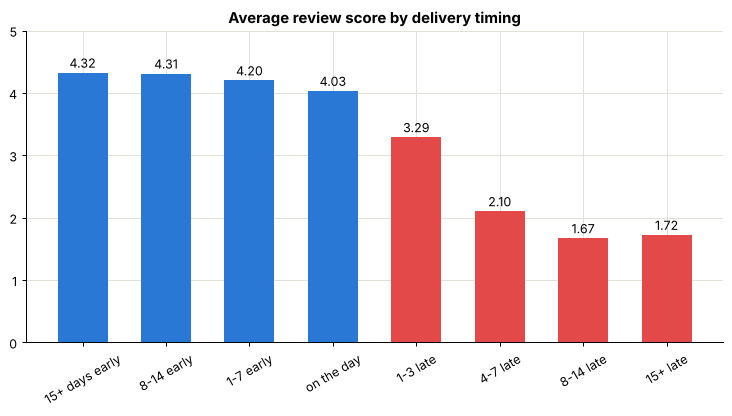

,orders,avg_review,pct_1_2_star
delay_bucket,,,
15+ days early,34693,4.32,9.00
8-14 early,36353,4.31,8.90
1-7 early,17335,4.20,10.23
on the day,1291,4.03,12.42
1-3 late,1869,3.29,32.14
4-7 late,1802,2.10,67.68
8-14 late,1478,1.67,80.15
15+ late,1382,1.72,78.32


In [15]:
bins = [-999, -15, -8, -1, 0, 3, 7, 14, 999]
labels = ["15+ days early", "8-14 early", "1-7 early", "on the day", "1-3 late", "4-7 late", "8-14 late", "15+ late"]
df["delay_bucket"] = pd.cut(df["delay_days"], bins=bins, labels=labels)
by_delay = df.groupby("delay_bucket", observed=True).agg(orders=("order_id", "count"), avg_review=("review_score", "mean"),
                                                         pct_1_2_star=("review_score", lambda s: (s.dropna() <= 2).mean() * 100))
fig, ax = plt.subplots()
colors = [BLUE] * 4 + [RED] * 4
ax.bar(by_delay.index.astype(str), by_delay["avg_review"], color=colors, width=0.6)
ax.set_ylim(0, 5)
ax.set_title("Average review score by delivery timing")
ax.tick_params(axis="x", rotation=30)
for i, v in enumerate(by_delay["avg_review"]):
    ax.text(i, v + 0.08, f"{v:.2f}", ha="center")
plt.show()
by_delay.round(2)

In [16]:
late = df.loc[df["is_late"] == 1, "review_score"].dropna()
ontime = df.loc[df["is_late"] == 0, "review_score"].dropna()
u, p = stats.mannwhitneyu(late, ontime, alternative="less")
bad = df["review_score"] <= 2
print(f"Average review: late {late.mean():.2f} vs on-time {ontime.mean():.2f}")
print(f"1-2 star reviews: late {(late <= 2).mean():.1%} vs on-time {(ontime <= 2).mean():.1%}")
print(f"Mann-Whitney U test (late scores lower): p = {p:.2e}")
print(f"Late orders are {df['is_late'].mean():.1%} of orders but {df.loc[bad, 'is_late'].mean():.1%} of all 1-2 star reviews")

Average review: late 2.27 vs on-time 4.29
1-2 star reviews: late 62.4% vs on-time 9.2%
Mann-Whitney U test (late scores lower): p = 0.00e+00
Late orders are 6.8% of orders but 32.6% of all 1-2 star reviews


**This is the central finding.** Scores fall off a cliff once an order is late. Late orders average about 2.3 stars against 4.3 for on-time orders, and about 6 in 10 late orders get a 1–2 star review. The difference is statistically significant: the Mann-Whitney test is used because review scores are ordinal, not normally distributed.

Late deliveries are only about 7% of orders, but they account for about a third of all bad reviews. Delivery reliability is the most direct lever on satisfaction in this data.

*Caveat:* this is observational. Lateness may also stand in for related problems, such as a seller with poor packaging or a remote region.

## 8. Customer retention

In [17]:
cust_orders = df.groupby("customer_unique_id")["order_id"].count()
dist = cust_orders.value_counts().sort_index()
print(f"Customers: {len(cust_orders):,}")
print(f"Repeat customers (2+ orders): {(cust_orders > 1).sum():,} = {(cust_orders > 1).mean():.2%}")
print(f"Revenue from repeat customers: {df[df['customer_unique_id'].isin(cust_orders[cust_orders > 1].index)]['order_value'].sum() / df['order_value'].sum():.1%}")
dist.rename("customers").to_frame().head(6)

Customers: 93,096
Repeat customers (2+ orders): 2,789 = 3.00%
Revenue from repeat customers: 5.6%


,customers
order_id,
1,90307
2,2562
3,180
4,28
5,9
6,5


Average month-1 retention: 0.45 %


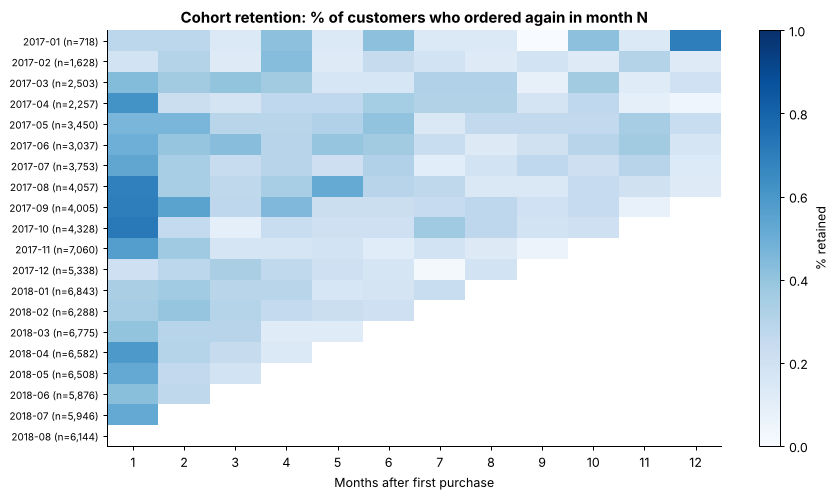

In [18]:
df["first_month"] = df.groupby("customer_unique_id")["order_purchase_timestamp"].transform("min").dt.to_period("M")
df["order_period"] = df["order_purchase_timestamp"].dt.to_period("M")
df["months_since_first"] = (df["order_period"] - df["first_month"]).apply(lambda d: d.n)

cohort_counts = (df.groupby(["first_month", "months_since_first"])["customer_unique_id"].nunique()
                 .unstack(fill_value=0))
cohort_size = cohort_counts[0]
retention = cohort_counts.div(cohort_size, axis=0) * 100
retention.index = retention.index.astype(str)

shown = retention.loc[:, 1:12]
fig, ax = plt.subplots(figsize=(11, 6))
# Hide months a cohort has not reached yet (they would show as 0%)
months_available = len(shown) - 1 - np.arange(len(shown))
observed = shown.columns.values[None, :] <= months_available[:, None]
im = ax.imshow(shown.where(observed), cmap="Blues", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(shown.columns)), shown.columns)
ax.set_yticks(range(len(shown.index)), [f"{i} (n={cohort_size.iloc[k]:,})" for k, i in enumerate(shown.index)], fontsize=8)
ax.set_xlabel("Months after first purchase")
ax.set_title("Cohort retention: % of customers who ordered again in month N")
ax.grid(False)
fig.colorbar(im, ax=ax, label="% retained")
plt.show()

cohort_out = retention.reset_index().melt(id_vars="first_month", var_name="months_since_first", value_name="retention_pct")
cohort_out = cohort_out.merge(cohort_size.rename("cohort_size").reset_index().assign(first_month=lambda d: d["first_month"].astype(str)), on="first_month")
cohort_out.to_csv(OUT + "cohort_retention.csv", index=False)
print("Average month-1 retention:", round(retention[1].mean(), 2), "%")

In [19]:
# How soon do repeat customers come back? Same-day "repeats" are usually one shopping trip split into two orders.
ordered = df.sort_values("order_purchase_timestamp")
ordered["order_number"] = ordered.groupby("customer_unique_id").cumcount() + 1
ordered["prev_purchase"] = ordered.groupby("customer_unique_id")["order_purchase_timestamp"].shift()
second = ordered[ordered["order_number"] == 2].copy()
second["gap_days"] = (second["order_purchase_timestamp"].dt.normalize() - second["prev_purchase"].dt.normalize()).dt.days
gap = pd.cut(second["gap_days"], [-1, 0, 30, 90, 180, 9999], labels=["same day", "1-30 days", "31-90 days", "91-180 days", "180+ days"])
same_day = (second["gap_days"] == 0).sum()
print(f"Second orders placed the same day as the first: {same_day:,} of {len(second):,}")
print(f"True return rate (came back on a later day): {(len(second) - same_day) / len(cust_orders):.2%}")
gap.value_counts().sort_index().rename("customers").to_frame()

Second orders placed the same day as the first: 827 of 2,789
True return rate (came back on a later day): 2.11%


,customers
gap_days,
same day,827
1-30 days,585
31-90 days,492
91-180 days,413
180+ days,472


Retention is extremely low. **Only 3% of customers place a second order, and about 30% of those 'repeats' happened on the same day as the first order** (a split basket, not a return visit). The true return rate is about 2.1%, and fewer than 0.5% come back in the month after their first purchase. Repeat customers bring in under 6% of revenue. Olist behaves like a one-time-purchase channel, so growth comes almost entirely from acquiring new customers. Even small gains in repeat rate would be valuable.

## 9. RFM customer segmentation

Classic RFM scores customers on **R**ecency, **F**requency and **M**onetary value. Because 97% of customers have exactly one order, frequency quintiles would be meaningless. Frequency is therefore treated as *repeat vs one-time*, and recency and monetary value are scored 1–5 with quintiles (`NTILE(5)` in SQL).

In [20]:
snapshot = df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)
rfm = df.groupby("customer_unique_id").agg(
    last_purchase=("order_purchase_timestamp", "max"),
    frequency=("order_id", "count"),
    monetary=("order_value", "sum"),
    state=("customer_state", "first"),
)
rfm["recency_days"] = (snapshot - rfm["last_purchase"]).dt.days
rfm["r_score"] = pd.qcut(rfm["recency_days"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["m_score"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

def segment(r):
    if r["frequency"] > 1:
        return "Loyal repeat" if r["r_score"] >= 3 else "Lapsed repeat"
    if r["r_score"] >= 4:
        return "New high-value" if r["m_score"] >= 4 else "New low-value"
    if r["r_score"] == 3:
        return "Cooling"
    return "At-risk high-value" if r["m_score"] >= 4 else "Hibernating"

rfm["segment"] = rfm.apply(segment, axis=1)
seg = rfm.groupby("segment").agg(customers=("frequency", "size"), avg_recency_days=("recency_days", "mean"),
                                 avg_orders=("frequency", "mean"), avg_spend=("monetary", "mean"), revenue=("monetary", "sum"))
seg["pct_customers"] = seg["customers"] / seg["customers"].sum() * 100
seg["pct_revenue"] = seg["revenue"] / seg["revenue"].sum() * 100
seg = seg.sort_values("revenue", ascending=False)
rfm.reset_index().drop(columns="last_purchase").to_csv(OUT + "customers_rfm.csv", index=False)
seg.round(1)

,customers,avg_recency_days,avg_orders,avg_spend,revenue,pct_customers,pct_revenue
segment,,,,,,,
New high-value,14380,91.1,1.0,302.1,4343918.3,15.4,28.3
At-risk high-value,13728,391.0,1.0,307.4,4220282.5,14.7,27.5
Cooling,18019,219.3,1.0,151.6,2731456.9,19.4,17.8
Hibernating,22517,393.2,1.0,72.7,1636700.9,24.2,10.6
New low-value,21663,89.6,1.0,72.9,1578849.2,23.3,10.3
Loyal repeat,1796,131.1,2.1,315.7,567060.7,1.9,3.7
Lapsed repeat,993,379.7,2.1,295.5,293472.5,1.1,1.9


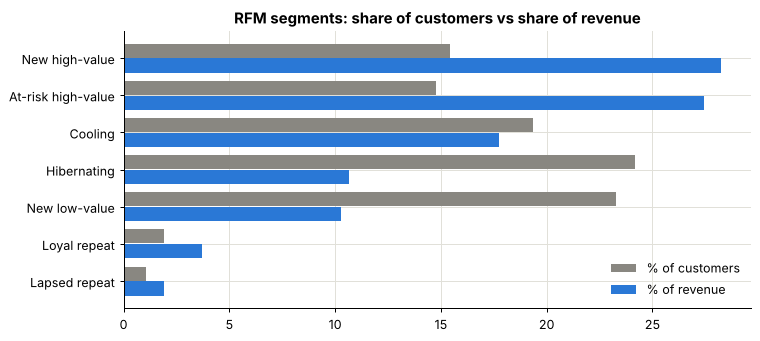

In [21]:
fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(seg))
ax.barh(y - 0.2, seg["pct_customers"], height=0.38, color=GREY, label="% of customers")
ax.barh(y + 0.2, seg["pct_revenue"], height=0.38, color=BLUE, label="% of revenue")
ax.set_yticks(y, seg.index)
ax.invert_yaxis()
ax.legend(frameon=False)
ax.set_title("RFM segments: share of customers vs share of revenue")
plt.show()

**How to act on each segment**

- **Loyal repeat / Lapsed repeat:** the rare customers (3%) who already came back. They spend about 2x the average customer. Keep them in loyalty and early-access programs.
- **New high-value:** recent big spenders. A post-delivery follow-up is the best chance to turn them into repeat buyers, especially if their delivery was on time.
- **At-risk high-value:** high spenders who haven't returned. Use win-back campaigns, and check first whether their order was late.
- **Hibernating / Cooling:** low priority for paid re-engagement.

## 10. Payments and instalments

payment_type
credit_card    0.755
boleto         0.199
voucher        0.031
debit_card     0.015
Name: proportion, dtype: float64


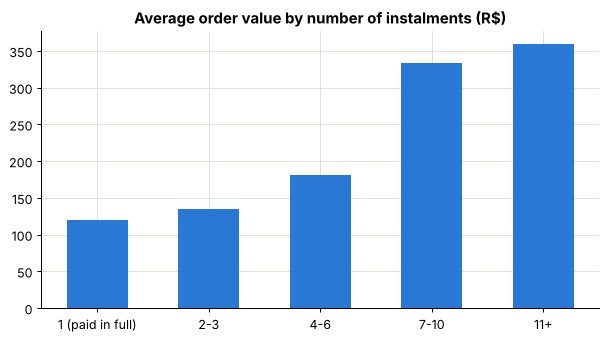

,orders,avg_order_value,median_order_value,avg_review
installment_band,,,,
1 (paid in full),46708,120.2,79.2,4.2
2-3,22098,135.4,111.8,4.1
4-6,15683,181.8,128.2,4.1
7-10,11385,333.3,205.9,4.1
11+,329,359.3,216.0,3.9


In [22]:
df["installment_band"] = pd.cut(df["installments"], [-1, 1, 3, 6, 10, 99], labels=["1 (paid in full)", "2-3", "4-6", "7-10", "11+"])
inst = df.groupby("installment_band", observed=True).agg(orders=("order_id", "count"), avg_order_value=("order_value", "mean"),
                                                         median_order_value=("order_value", "median"), avg_review=("review_score", "mean"))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(inst.index.astype(str), inst["avg_order_value"], color=BLUE, width=0.55)
ax.set_title("Average order value by number of instalments (R$)")
plt.show()
print(df["payment_type"].value_counts(normalize=True).round(3))
inst.round(1)

Instalments are tied to much larger baskets. Orders split into 7+ instalments average almost 3x the value of orders paid in full. Credit cards carry about 76% of orders, and boleto (bank slip) about 20%. Promoting interest-free instalments on high-ticket categories is a lever worth A/B testing. This is correlation: people buying expensive items choose instalments, so the causal effect is unproven.

## 11. Key findings

In [23]:
findings = {
    "Late delivery rate": f"{df['is_late'].mean():.1%}",
    "Avg review, on time vs late": f"{ontime.mean():.2f} vs {late.mean():.2f}",
    "1-2 star share, on time vs late": f"{(ontime <= 2).mean():.0%} vs {(late <= 2).mean():.0%}",
    "Late orders' share of all 1-2 star reviews": f"{df.loc[bad, 'is_late'].mean():.0%}",
    "Peak monthly late rate": f"{monthly['late_rate'].max():.0%} ({monthly['late_rate'].idxmax()})",
    "Median days delivered before estimate": f"{-df['delay_days'].median():.0f}",
    "Repeat customer rate (any 2nd order)": f"{(cust_orders > 1).mean():.1%}",
    "True return rate (2nd order on a later day)": f"{(len(second) - same_day) / len(cust_orders):.1%}",
    "AOV, paid in full vs 7-10 instalments": f"R${inst.iloc[0]['avg_order_value']:.0f} vs R${inst.iloc[3]['avg_order_value']:.0f}",
}
pd.Series(findings, name="value").to_frame()

,value
Late delivery rate,6.8%
"Avg review, on time vs late",4.29 vs 2.27
"1-2 star share, on time vs late",9% vs 62%
Late orders' share of all 1-2 star reviews,33%
Peak monthly late rate,19% (2018-03)
Median days delivered before estimate,12
Repeat customer rate (any 2nd order),3.0%
True return rate (2nd order on a later day),2.1%
"AOV, paid in full vs 7-10 instalments",R$120 vs R$333


**Recommendations**

1. **Treat on-time delivery as the top satisfaction KPI.** Lateness concentrates bad reviews, so add capacity, or seller and carrier SLAs, ahead of known peaks like Black Friday.
2. **Fix the regional gap.** Prioritise logistics partners or regional fulfilment for the North and Northeast, where delivery is slowest and late rates are highest.
3. **Tighten delivery estimates.** Estimates are about 12 days too long for the typical order. A more accurate promise may lift conversion, but test it so that lateness doesn't rise.
4. **Build a second-purchase program.** With only about 2% of customers genuinely returning, even a 1-point gain in repeat rate is meaningful. Target *New high-value* customers right after an on-time delivery.
5. **Use instalments as a basket-size lever** on high-ticket categories, validated with an A/B test.

**Limitations:** this is observational data, so the patterns show association, not causation. Reviews are missing for some orders. Revenue excludes cancelled orders.